các thư viện cần thiết

In [ ]:
import pandas as pd
from itertools import combinations
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np
import seaborn as sns
import pandas as pd
import re


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# chuẩn bị và  Điều chỉnh dataset


từ 12,981 dòng đã tăng lên 45,000 dòng.

Biểu đồ cho tập train đã được lưu vào tệp 'sentiment_distribution_train.png'


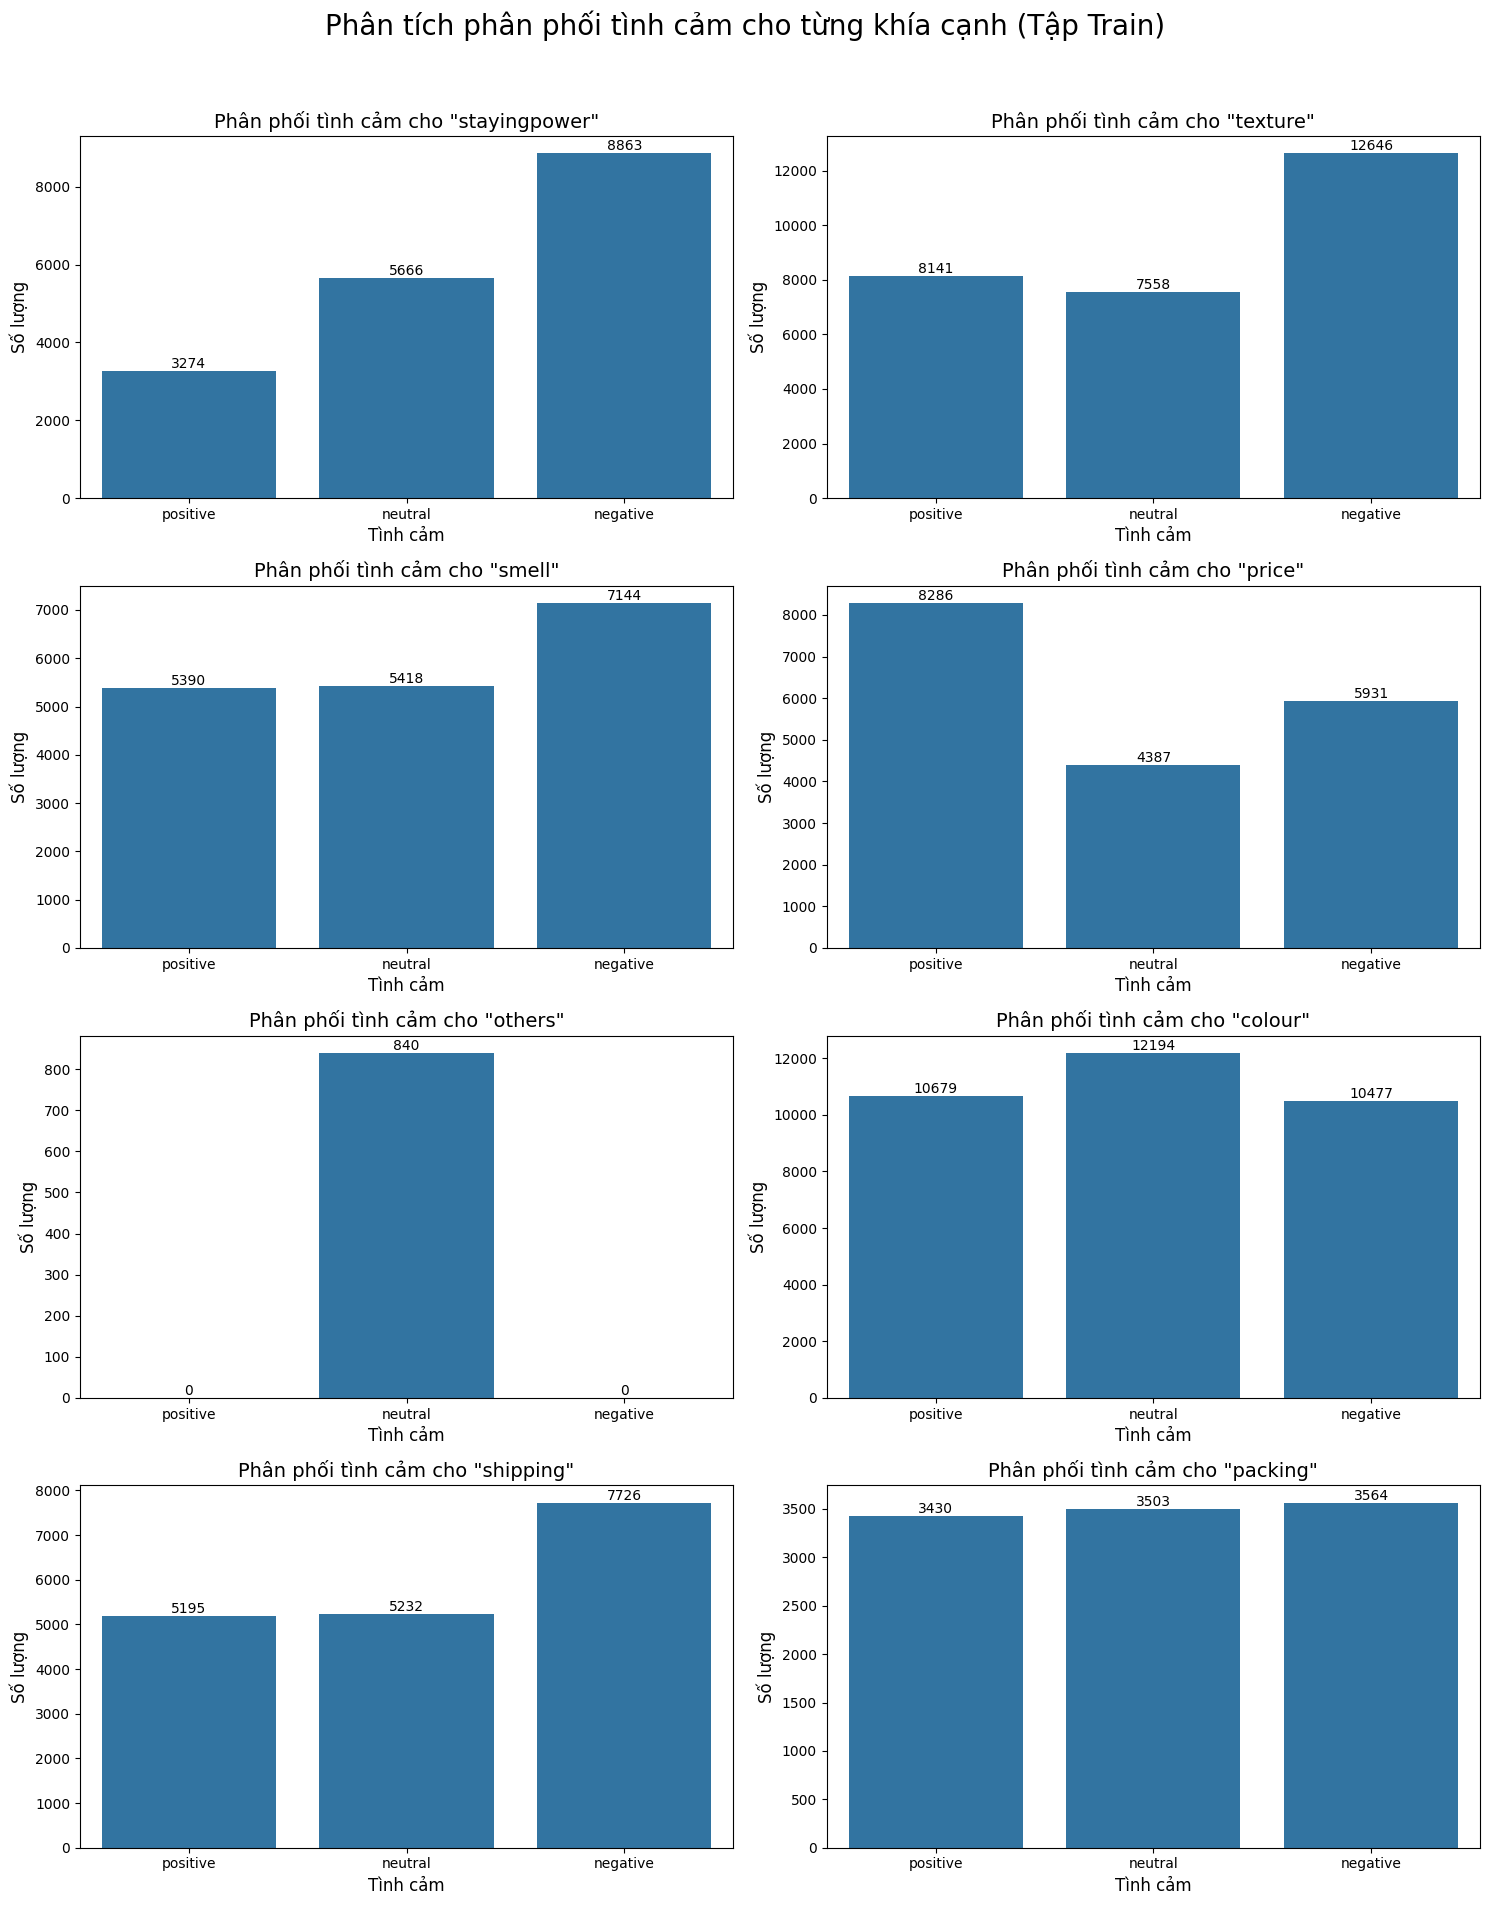

In [ ]:
# Tải bộ dữ liệu huấn luyện (train)
df_train = pd.read_csv('/content/drive/MyDrive/XlNNTN (TH)/train_data_balanced_sampled (1).csv')

# Danh sách các cột khía cạnh cần phân tích
aspect_columns = ['stayingpower', 'texture', 'smell', 'price', 'others', 'colour', 'shipping', 'packing']

# --- Đếm số lượng tình cảm cho mỗi khía cạnh ---
sentiment_counts = {}
for col in aspect_columns:
    # Đếm số lần xuất hiện của mỗi giá trị (positive, neutral, negative)
    sentiment_counts[col] = df_train[col].value_counts()

# --- Trực quan hóa dữ liệu ---
# Tạo một figure lớn chứa 8 biểu đồ nhỏ (4 hàng, 2 cột)
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15, 20))
fig.suptitle('Phân tích phân phối tình cảm cho từng khía cạnh (Tập Train)', fontsize=20)

# Làm phẳng mảng axes để dễ dàng lặp qua
axes = axes.flatten()

# Vẽ biểu đồ cột cho từng khía cạnh
for i, col in enumerate(aspect_columns):
    # Lấy dữ liệu đếm của khía cạnh hiện tại
    counts = sentiment_counts[col]

    # Sử dụng seaborn để vẽ biểu đồ cột, sắp xếp theo thứ tự mong muốn
    sns.barplot(x=counts.index, y=counts.values, ax=axes[i], order=['positive', 'neutral', 'negative'])

    # Thiết lập tiêu đề và nhãn cho từng biểu đồ
    axes[i].set_title(f'Phân phối tình cảm cho "{col}"', fontsize=14)
    axes[i].set_xlabel('Tình cảm', fontsize=12)
    axes[i].set_ylabel('Số lượng', fontsize=12)

    # Thêm số lượng trên đỉnh mỗi cột
    # Sắp xếp lại và điền 0 cho các giá trị tình cảm không có để hiển thị đúng
    for index, value in enumerate(counts.reindex(['positive', 'neutral', 'negative']).fillna(0)):
        axes[i].text(index, value + 0.1, str(int(value)), ha='center', va='bottom')

# Tự động điều chỉnh khoảng cách giữa các biểu đồ con
plt.tight_layout(rect=[0, 0.03, 1, 0.96])

# Lưu biểu đồ thành tệp ảnh
plt.savefig('sentiment_distribution_train.png')

print("Biểu đồ cho tập train đã được lưu vào tệp 'sentiment_distribution_train.png'")

xóa cột others ở train

tăng cường dữ liêu j???

In [ ]:
import pandas as pd

# --- THAY ĐỔI TÊN TỆP NẾU CẦN ---
input_filename = '/content/drive/MyDrive/XlNNTN (TH)/train_data_balanced_sampled (1).csv'
output_filename = 'train_data_final.csv'

try:
    # 1. Tải dữ liệu từ tệp CSV
    print(f"Đang đọc dữ liệu từ tệp '{input_filename}'...")
    df = pd.read_csv(input_filename, low_memory=False)
    print("Các cột ban đầu:", df.columns.tolist())

    # 2. Xóa cột 'others'
    # 'axis=1' chỉ định rằng chúng ta đang xóa một cột
    if 'others' in df.columns:
        df_modified = df.drop('others', axis=1)
        print("\nĐã xóa thành công cột 'others'.")
    else:
        df_modified = df # Không có cột 'others' để xoá
        print("\nKhông tìm thấy cột 'others' trong dữ liệu.")

    print("Các cột còn lại:", df_modified.columns.tolist())

    # 3. Lưu DataFrame đã chỉnh sửa vào một tệp CSV mới
    df_modified.to_csv(output_filename, index=False)
    print(f"\nĐã lưu dữ liệu mới vào tệp '{output_filename}'.")

except FileNotFoundError:
    print(f"Lỗi: Không tìm thấy tệp '{input_filename}'. Vui lòng kiểm tra lại tên và đường dẫn tệp.")

Đang đọc dữ liệu từ tệp '/content/drive/MyDrive/XlNNTN (TH)/train_data_balanced_sampled (1).csv'...
Các cột ban đầu: ['data', 'stayingpower', 'texture', 'smell', 'price', 'others', 'colour', 'shipping', 'packing']

Đã xóa thành công cột 'others'.
Các cột còn lại: ['data', 'stayingpower', 'texture', 'smell', 'price', 'colour', 'shipping', 'packing']

Đã lưu dữ liệu mới vào tệp 'train_data_final.csv'.


hiển thị train data sau khi xóa cột others

Đang đọc dữ liệu từ tệp 'train_data_final.csv'...

Biểu đồ đã được lưu vào tệp 'final_distribution.png'


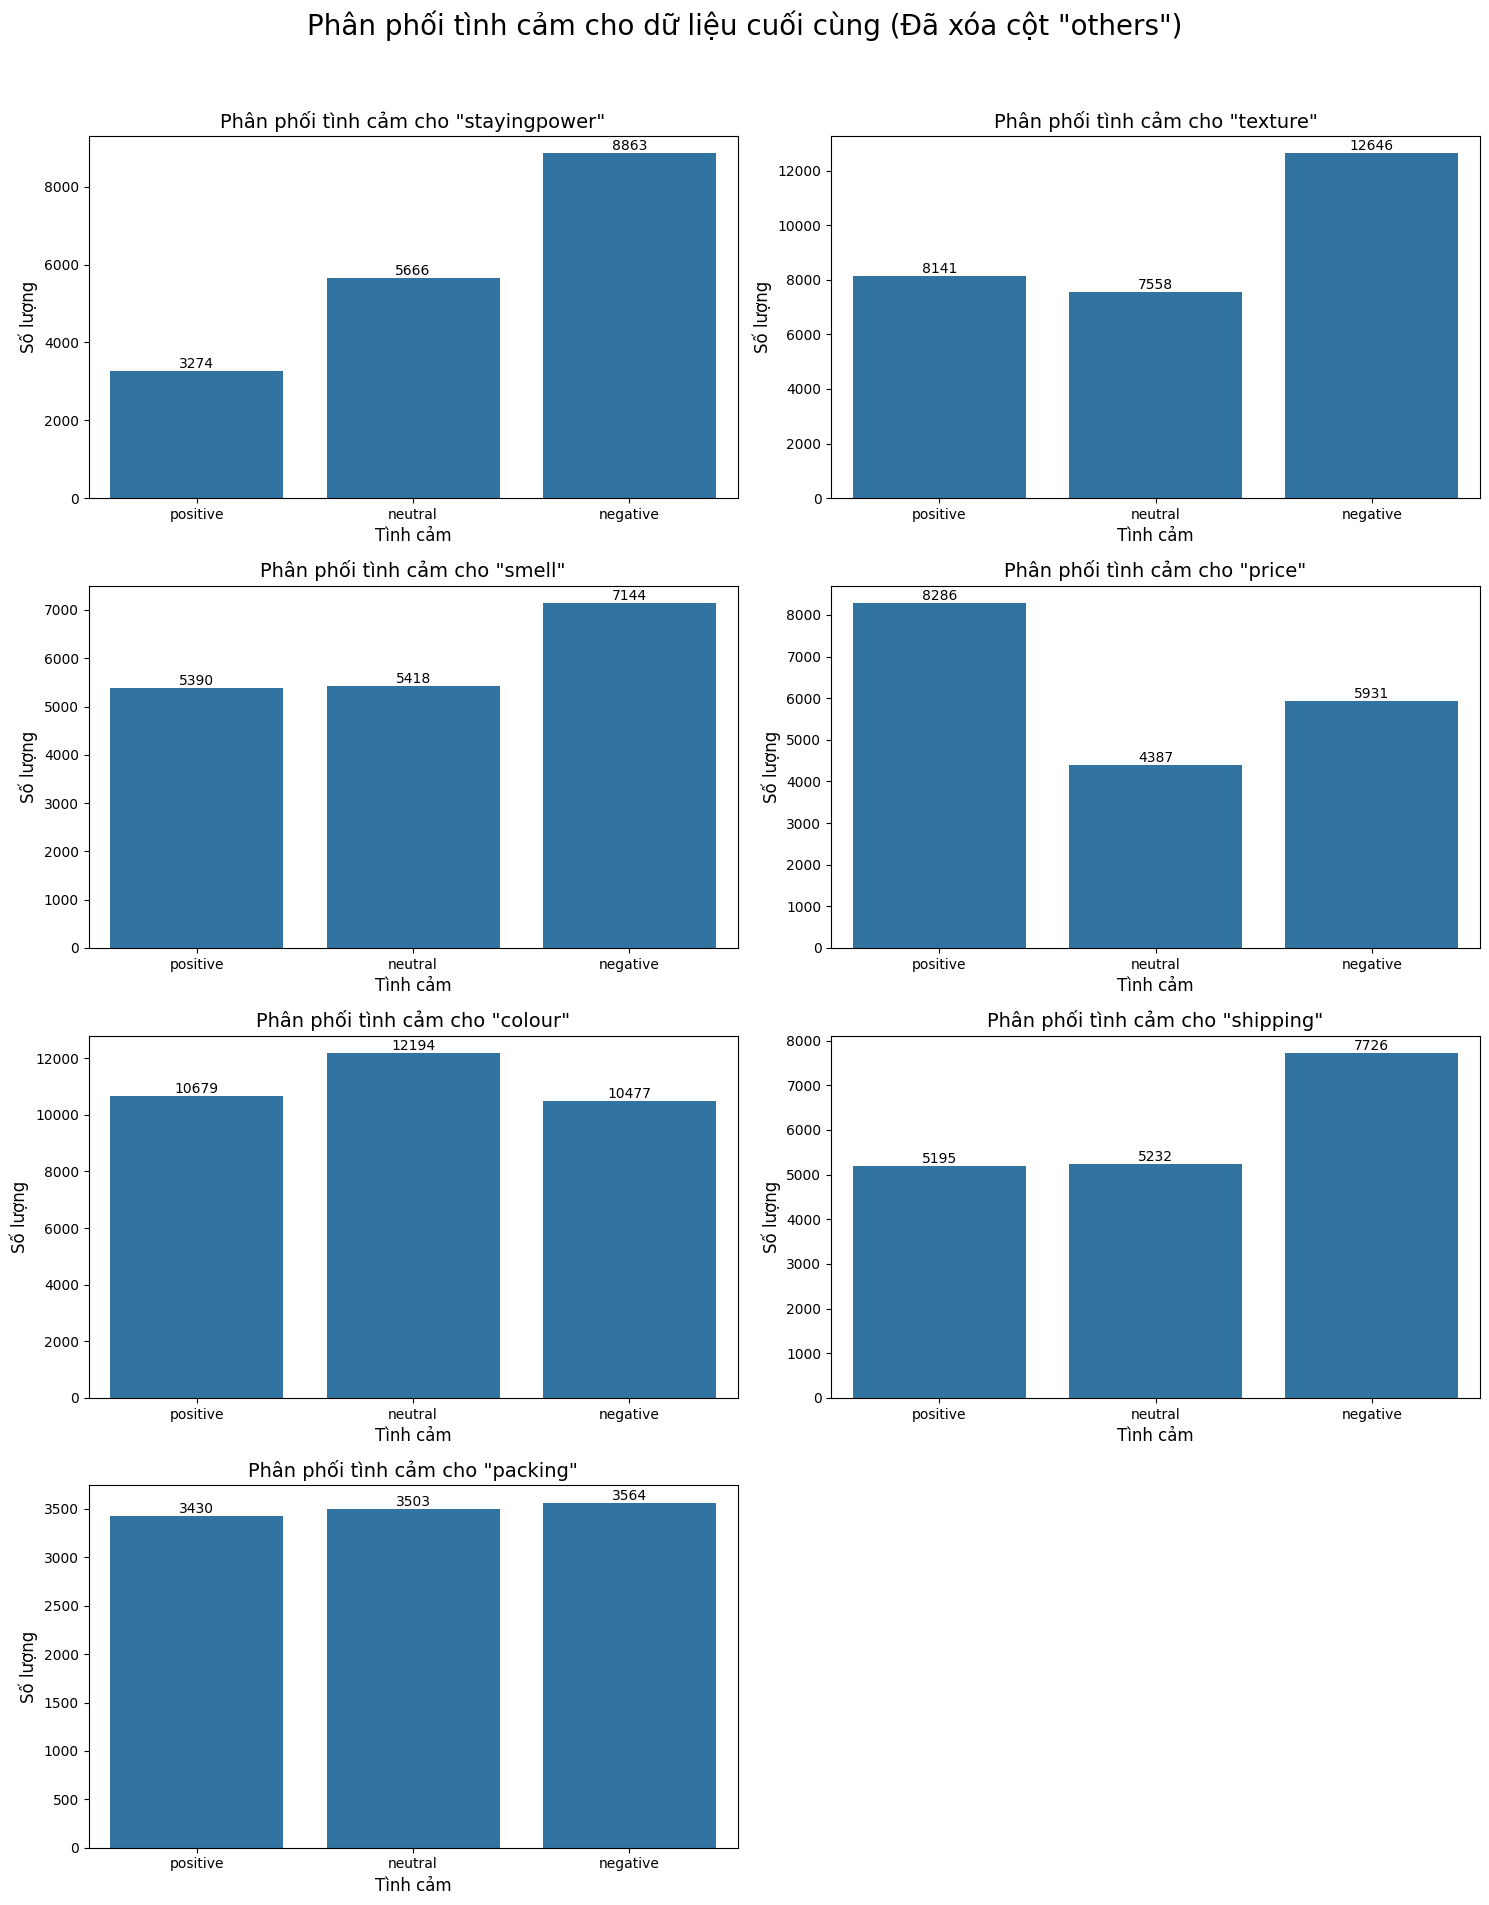

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tên tệp dữ liệu cuối cùng của bạn
input_filename = 'train_data_final.csv'

try:
    # 1. Tải dữ liệu từ tệp CSV
    print(f"Đang đọc dữ liệu từ tệp '{input_filename}'...")
    df = pd.read_csv(input_filename, low_memory=False)

    # 2. Các khía cạnh còn lại để vẽ biểu đồ (đã bỏ 'others')
    aspect_columns = ['stayingpower', 'texture', 'smell', 'price', 'colour', 'shipping', 'packing']

    # 3. Thiết lập và vẽ biểu đồ
    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15, 20))
    fig.suptitle('Phân phối tình cảm cho dữ liệu cuối cùng (Đã xóa cột "others")', fontsize=20)
    axes = axes.flatten() # Làm phẳng mảng axes để dễ lặp

    for i, col in enumerate(aspect_columns):
        counts = df[col].value_counts()

        sns.barplot(x=counts.index, y=counts.values, ax=axes[i], order=['positive', 'neutral', 'negative'])

        axes[i].set_title(f'Phân phối tình cảm cho "{col}"', fontsize=14)
        axes[i].set_xlabel('Tình cảm', fontsize=12)
        axes[i].set_ylabel('Số lượng', fontsize=12)

        # Thêm số đếm trên mỗi cột
        for index, value in enumerate(counts.reindex(['positive', 'neutral', 'negative']).fillna(0)):
            axes[i].text(index, value + 0.1, str(int(value)), ha='center', va='bottom')

    # Ẩn ô biểu đồ cuối cùng không được sử dụng
    fig.delaxes(axes[7])

    plt.tight_layout(rect=[0, 0.03, 1, 0.96])

    # Lưu và hiển thị biểu đồ
    plt.savefig('final_distribution.png')
    print("\nBiểu đồ đã được lưu vào tệp 'final_distribution.png'")
    plt.show()

except FileNotFoundError:
    print(f"Lỗi: Không tìm thấy tệp '{input_filename}'. Hãy chắc chắn bạn đã chạy code xóa cột trước đó.")

In [ ]:
import pandas as pd

# Danh sách các tệp cần xử lý
files_to_process = {
    '/content/drive/MyDrive/XlNNTN (TH)/data_val.csv': 'val_data_final.csv',
    '/content/drive/MyDrive/XlNNTN (TH)/data_test.csv': 'test_data_final.csv'
}

print("Bắt đầu xử lý tệp validation và test...")

# Lặp qua từng tệp để xử lý
for input_file, output_file in files_to_process.items():
    try:
        # 1. Đọc dữ liệu từ tệp
        print(f"\n--- Đang đọc tệp: {input_file} ---")
        df = pd.read_csv(input_file)
        print("Các cột ban đầu:", df.columns.tolist())

        # 2. Xóa cột 'others' nếu nó tồn tại
        if 'others' in df.columns:
            df_modified = df.drop('others', axis=1)
            print("Đã xóa thành công cột 'others'.")
        else:
            df_modified = df
            print("Không tìm thấy cột 'others' trong tệp này.")

        print("Các cột còn lại:", df_modified.columns.tolist())

        # 3. Lưu dữ liệu đã xử lý vào tệp mới
        df_modified.to_csv(output_file, index=False)
        print(f"Đã lưu dữ liệu mới vào tệp '{output_file}'.")

    except FileNotFoundError:
        print(f"LỖI: Không tìm thấy tệp '{input_file}'. Vui lòng đảm bảo tệp tồn tại trong cùng thư mục.")

print("\nHoàn tất! Cả ba bộ dữ liệu (train, val, test) giờ đã đồng bộ và sẵn sàng để huấn luyện mô hình.")

Bắt đầu xử lý tệp validation và test...

--- Đang đọc tệp: /content/drive/MyDrive/XlNNTN (TH)/data_val.csv ---
Các cột ban đầu: ['data', 'stayingpower', 'texture', 'smell', 'price', 'others', 'colour', 'shipping', 'packing']
Đã xóa thành công cột 'others'.
Các cột còn lại: ['data', 'stayingpower', 'texture', 'smell', 'price', 'colour', 'shipping', 'packing']
Đã lưu dữ liệu mới vào tệp 'val_data_final.csv'.

--- Đang đọc tệp: /content/drive/MyDrive/XlNNTN (TH)/data_test.csv ---
Các cột ban đầu: ['data', 'stayingpower', 'texture', 'smell', 'price', 'others', 'colour', 'shipping', 'packing']
Đã xóa thành công cột 'others'.
Các cột còn lại: ['data', 'stayingpower', 'texture', 'smell', 'price', 'colour', 'shipping', 'packing']
Đã lưu dữ liệu mới vào tệp 'test_data_final.csv'.

Hoàn tất! Cả ba bộ dữ liệu (train, val, test) giờ đã đồng bộ và sẵn sàng để huấn luyện mô hình.


xóa cột others

--- Đang xử lý tệp: val_data_final.csv ---
Đã lưu biểu đồ vào tệp: distribution_val.png



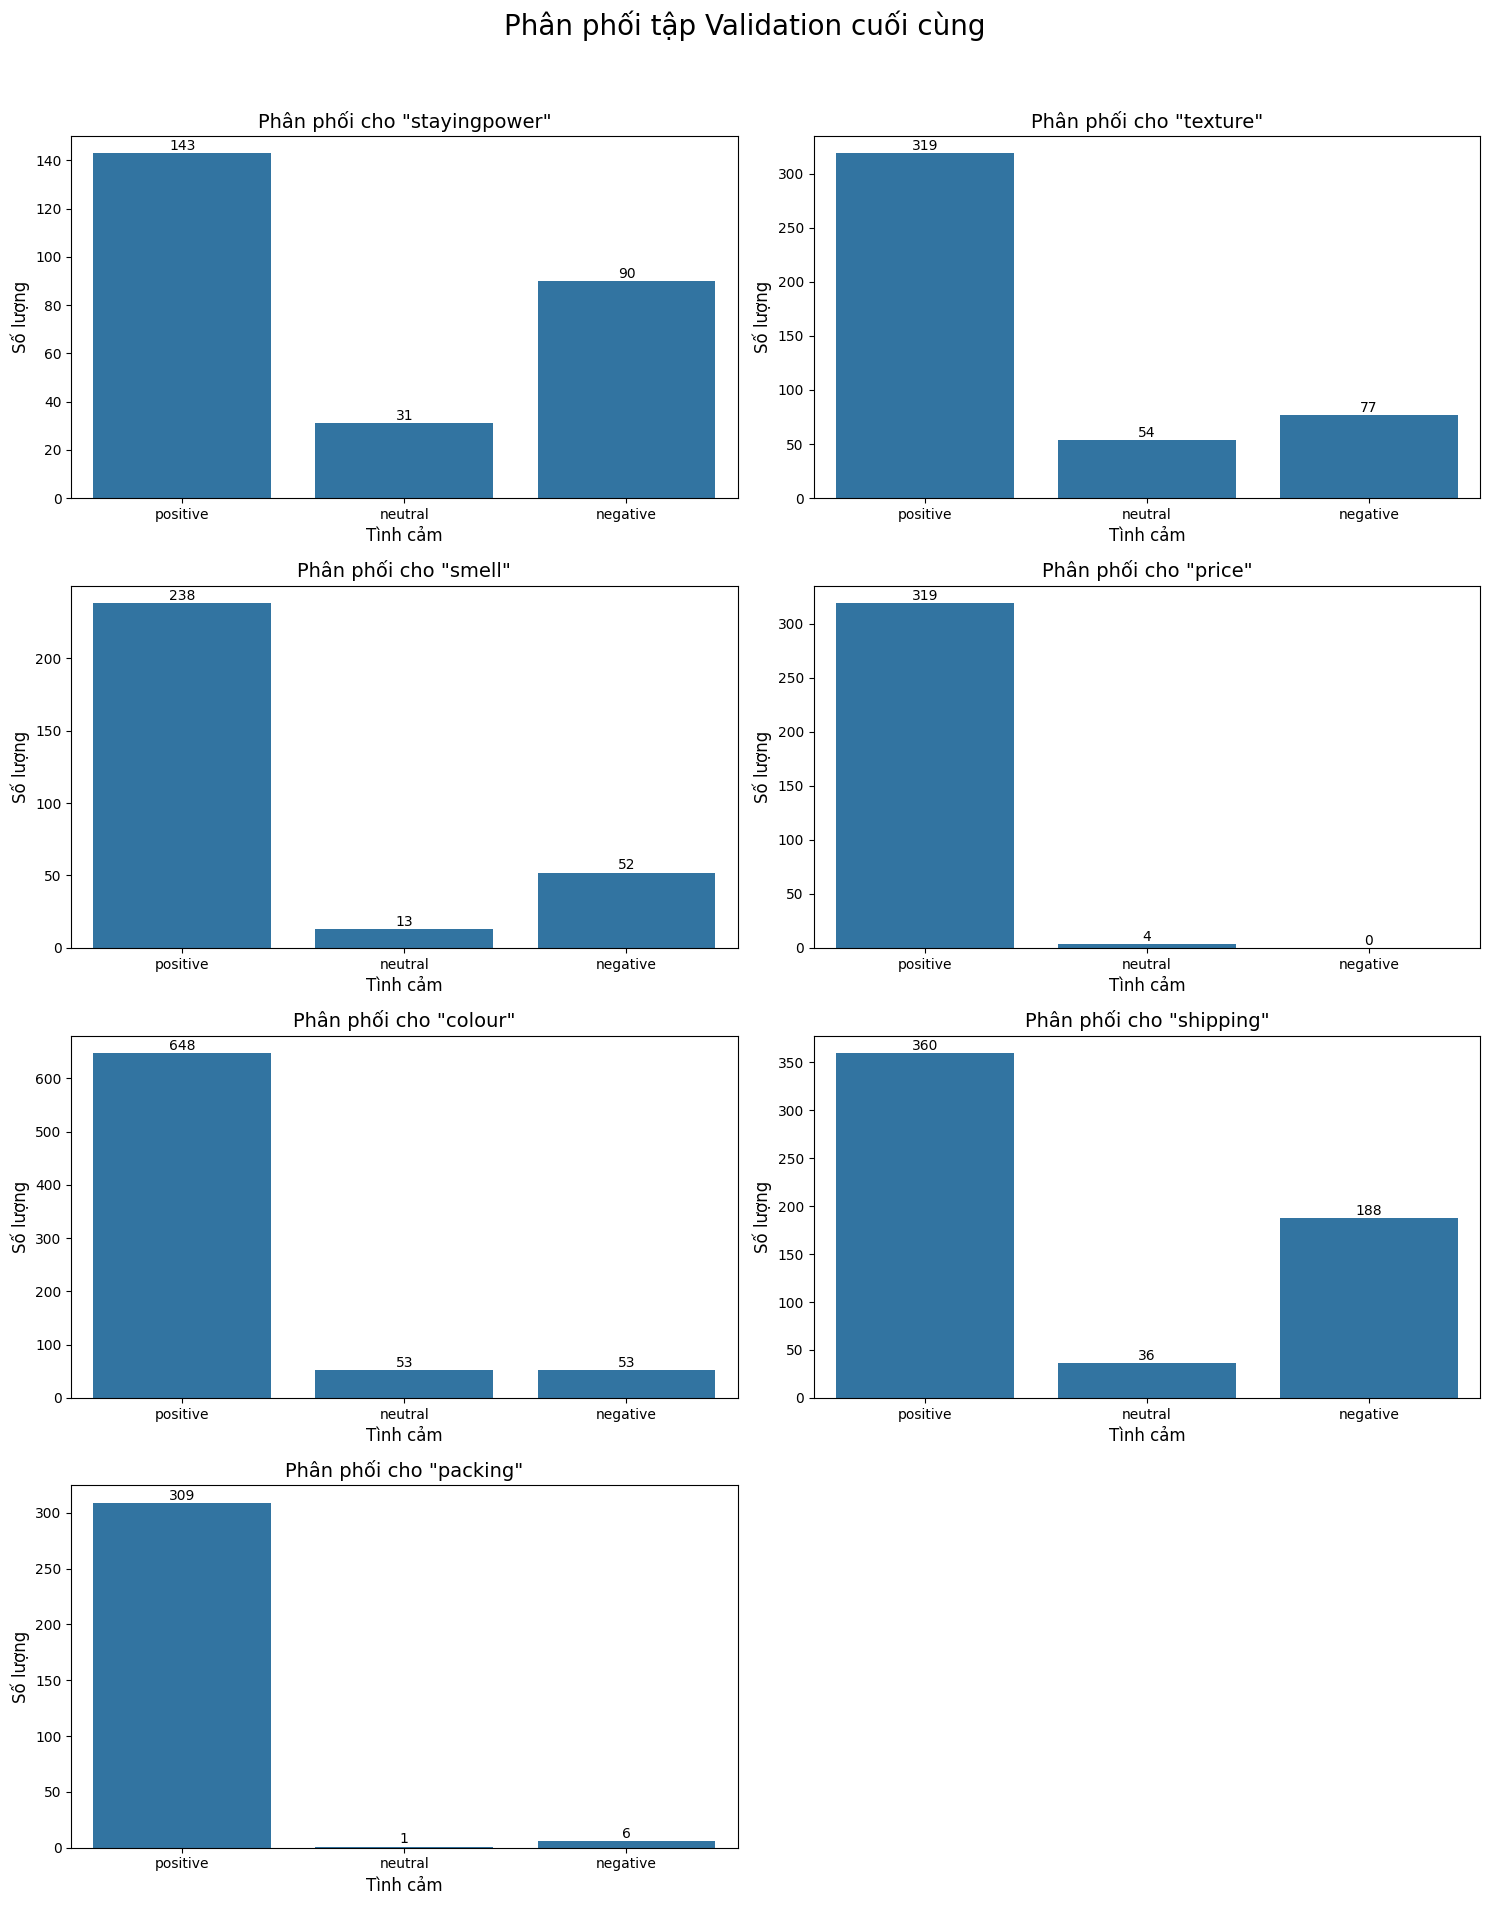

In [ ]:
# Tên tệp validation
filename = 'val_data_final.csv'
title = 'Phân phối tập Validation cuối cùng'
output_image_filename = 'distribution_val.png'
aspect_columns = ['stayingpower', 'texture', 'smell', 'price', 'colour', 'shipping', 'packing']

try:
    # 1. Đọc dữ liệu
    print(f"--- Đang xử lý tệp: {filename} ---")
    df = pd.read_csv(filename)

    # 2. Thiết lập và vẽ biểu đồ
    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15, 20))
    fig.suptitle(title, fontsize=20)
    axes = axes.flatten()

    for i, col in enumerate(aspect_columns):
        counts = df[col].value_counts()
        sns.barplot(x=counts.index, y=counts.values, ax=axes[i], order=['positive', 'neutral', 'negative'])
        axes[i].set_title(f'Phân phối cho "{col}"', fontsize=14)
        axes[i].set_xlabel('Tình cảm', fontsize=12)
        axes[i].set_ylabel('Số lượng', fontsize=12)

        for index, value in enumerate(counts.reindex(['positive', 'neutral', 'negative']).fillna(0)):
            axes[i].text(index, value + 0.1, str(int(value)), ha='center', va='bottom')

    fig.delaxes(axes[7])
    plt.tight_layout(rect=[0, 0.03, 1, 0.96])

    # 3. Lưu và hiển thị
    plt.savefig(output_image_filename)
    print(f"Đã lưu biểu đồ vào tệp: {output_image_filename}\n")
    plt.show()

except FileNotFoundError:
    print(f"LỖI: Không tìm thấy tệp '{filename}'.")

xóa cột others ở test

--- Đang xử lý tệp: test_data_final.csv ---
Đã lưu biểu đồ vào tệp: distribution_test.png



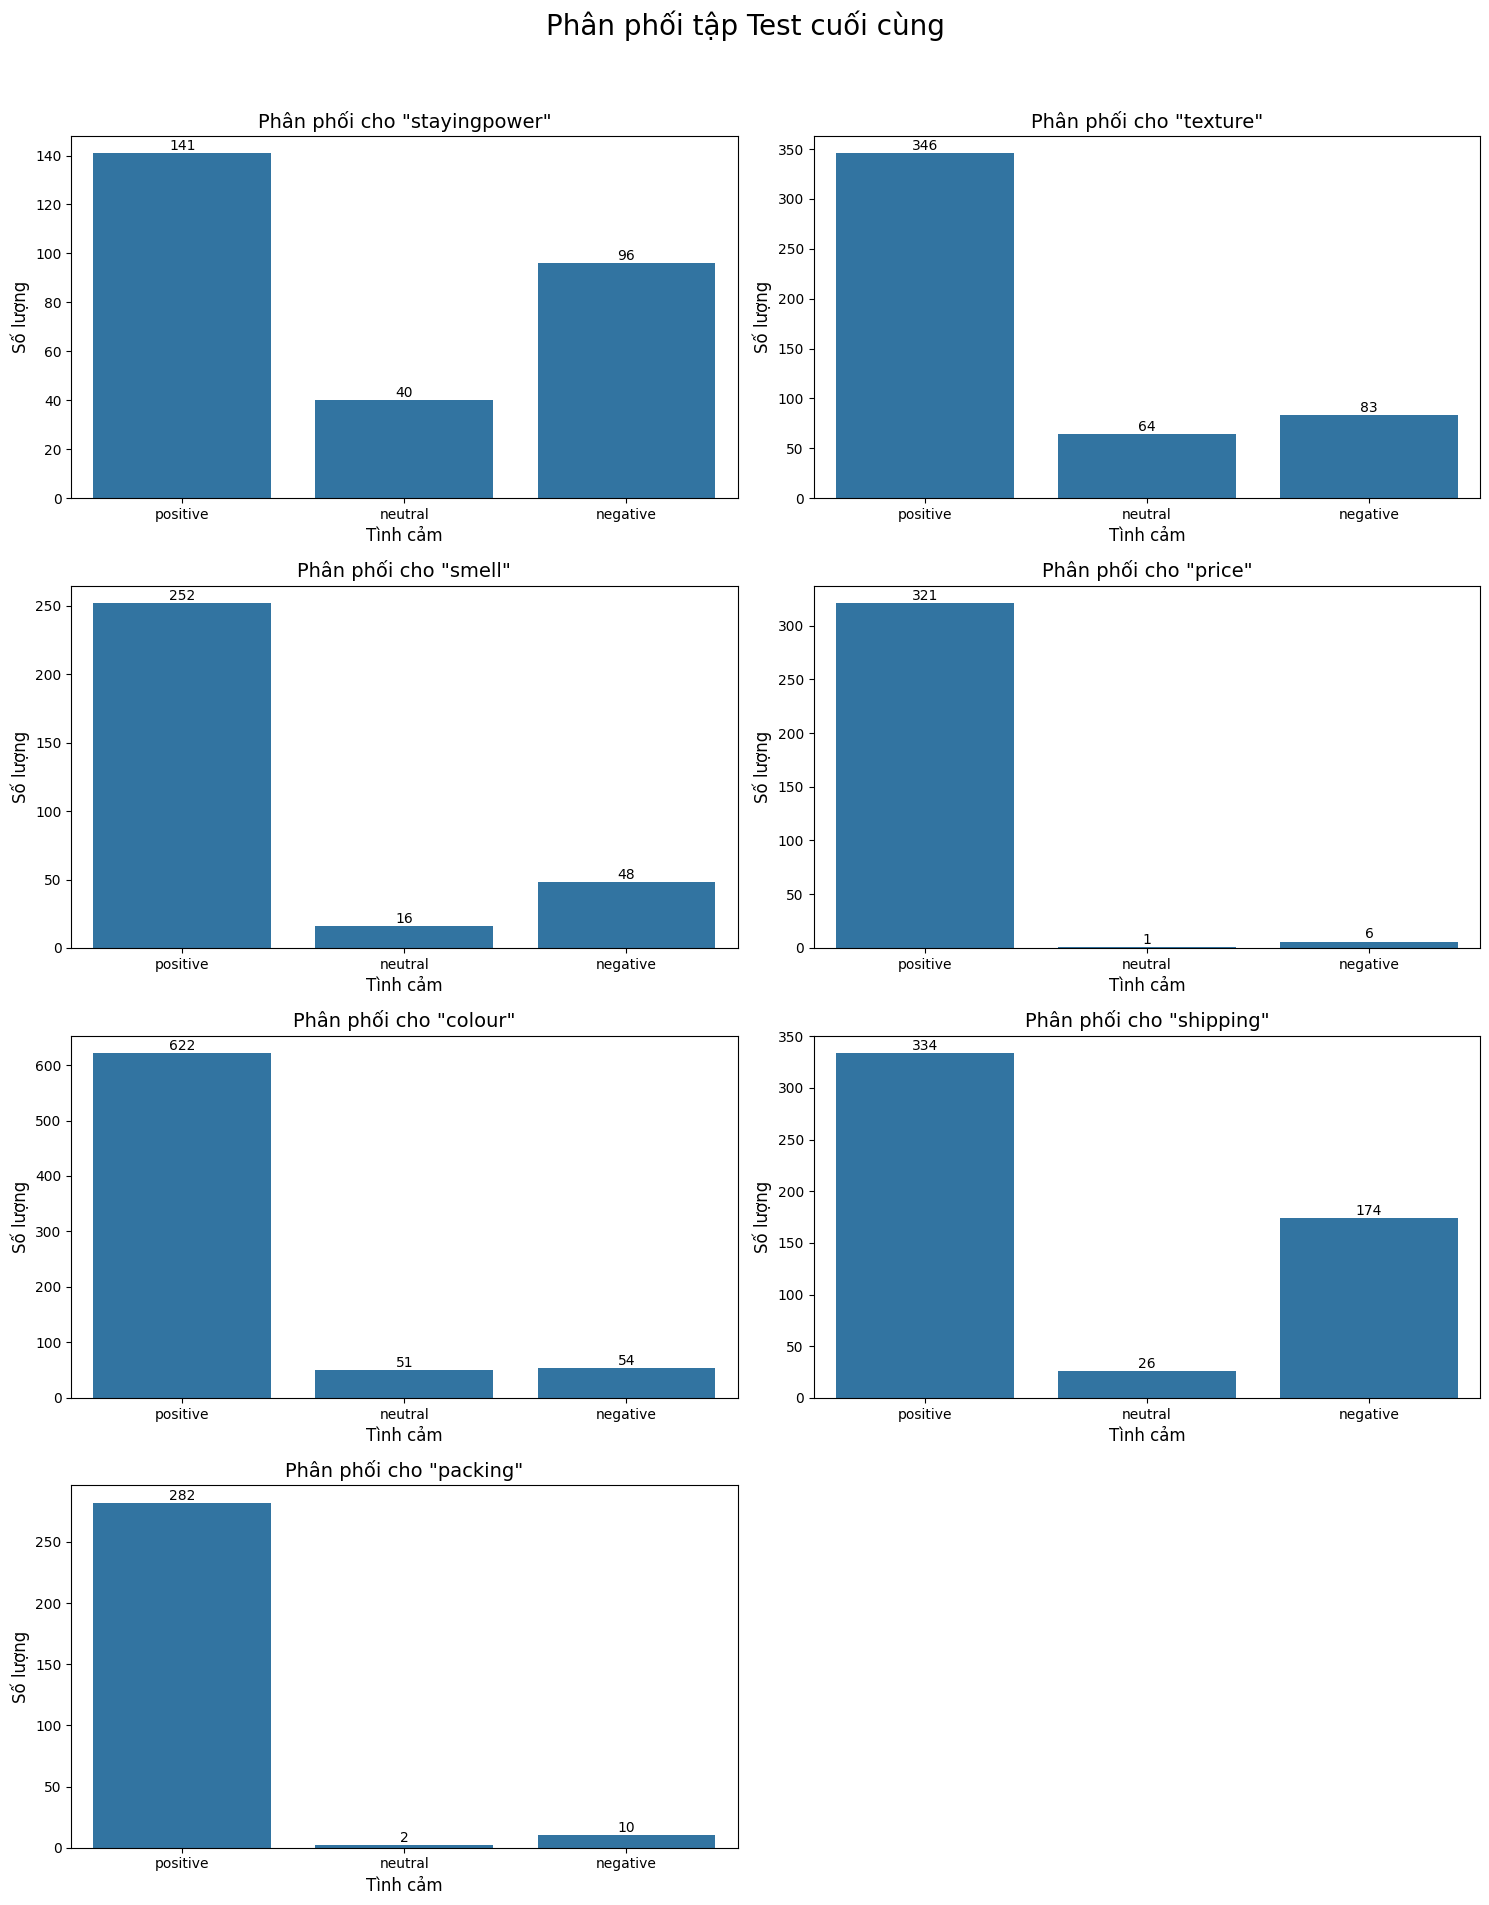

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tên tệp test
filename = 'test_data_final.csv'
title = 'Phân phối tập Test cuối cùng'
output_image_filename = 'distribution_test.png'
aspect_columns = ['stayingpower', 'texture', 'smell', 'price', 'colour', 'shipping', 'packing']

try:
    # 1. Đọc dữ liệu
    print(f"--- Đang xử lý tệp: {filename} ---")
    df = pd.read_csv(filename)

    # 2. Thiết lập và vẽ biểu đồ
    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15, 20))
    fig.suptitle(title, fontsize=20)
    axes = axes.flatten()

    for i, col in enumerate(aspect_columns):
        counts = df[col].value_counts()
        sns.barplot(x=counts.index, y=counts.values, ax=axes[i], order=['positive', 'neutral', 'negative'])
        axes[i].set_title(f'Phân phối cho "{col}"', fontsize=14)
        axes[i].set_xlabel('Tình cảm', fontsize=12)
        axes[i].set_ylabel('Số lượng', fontsize=12)

        for index, value in enumerate(counts.reindex(['positive', 'neutral', 'negative']).fillna(0)):
            axes[i].text(index, value + 0.1, str(int(value)), ha='center', va='bottom')

    fig.delaxes(axes[7])
    plt.tight_layout(rect=[0, 0.03, 1, 0.96])

    # 3. Lưu và hiển thị
    plt.savefig(output_image_filename)
    print(f"Đã lưu biểu đồ vào tệp: {output_image_filename}\n")
    plt.show()

except FileNotFoundError:
    print(f"LỖI: Không tìm thấy tệp '{filename}'.")

# tiền xử lý dữ liệu


In [ ]:
# !pip install transformers[torch]
# !pip install accelerate
# !pip install py_vncorenlp

In [ ]:
# Hãy chạy dòng này để xem tất cả tên cột trong DataFrame của bạn
print(df_train.columns)

Index(['data', 'stayingpower', 'texture', 'smell', 'price', 'others', 'colour',
       'shipping', 'packing'],
      dtype='object')


In [ ]:
# Câu ví dụ gốc
text = "Sản phẩm TỐT lắmmmm 🥰👌 Cảm ơn shop nhiều <3, xem thêm tại https://shop.vn/sp"

print("Câu gốc:")
print(text)

Câu gốc:
Sản phẩm TỐT lắmmmm 🥰👌 Cảm ơn shop nhiều <3, xem thêm tại https://shop.vn/sp


In [ ]:
# Từ điển phân loại icon/emoticon
emoji_dict = {
    "emoji_positive": [
        ":)", ":-)", ":D", "<3", "hihi", "haha", "hehe", "🥰", "😊", "😁", "😄", "😃", "😆", "😎", "😍", "😘",
        "😚", "😙", "😇", "🤗", "😻", "😸", "😺", "🎉", "✨", "🌟", "💖", "💕", "💞", "💗", "💓", "💘", "💝",
        "🙌", "👍", "👌", "💐", "💃", "🕺", "😋", "😜", "😝", "😛", "😹", "😂", "🤣", "🤩", "🥳", "🫶", "❤️"
    ],
    "emoji_negative": [
        ":(", ":-(", "😕", "💔", "😢", "😭", "😞", "😔", "😟", "😣", "😩", "😫", "😖", "🥺", "🙁", "😤", "😰",
        "😱", "🤬", "😡", "😠", "👿", "👎", "😿", "😾", "😓", "😥", "💢", "😧", "😨", "😵", "🥵", "🥶", "😶‍🌫️"
    ],
    "emoji_neutral": [
        ":|", ":p", "😐", "😶", "😑", "😒", "😬", "😌", "🤔", "🧐", "😴", "😪", "😗", "🙄", "🤨", "😶‍🌫️", "🫤",
        "😵‍💫", "😏", "🙃", "😯", "😮", "😲"
    ]
}

print("Từ điển Emoji đã được tạo.")

Từ điển Emoji đã được tạo.


In [ ]:
# Tạo một bản sao để xử lý
processed_text = text

# Vòng lặp để thay thế
for sentiment, icons in emoji_dict.items():
    for icon in icons:
        # Thêm khoảng trắng xung quanh thẻ để tách biệt
        processed_text = processed_text.replace(icon, f" {sentiment} ")

print("Kết quả sau Bước 1 (Thay thế Emoji):")
print(processed_text)

Kết quả sau Bước 1 (Thay thế Emoji):
Sản phẩm TỐT lắmmmm  emoji_positive  emoji_positive  Cảm ơn shop nhiều  emoji_positive , xem thêm tại https://shop.vn/sp


In [ ]:
processed_text = processed_text.lower()

print("Kết quả sau Bước 2 (Chuyển về chữ thường):")
print(processed_text)

Kết quả sau Bước 2 (Chuyển về chữ thường):
sản phẩm tốt lắmmmm  emoji_positive  emoji_positive  cảm ơn shop nhiều  emoji_positive , xem thêm tại https://shop.vn/sp


In [ ]:
processed_text = re.sub(r'http\S+', ' ', processed_text)

print("Kết quả sau Bước 3 (Loại bỏ URL):")
print(processed_text)

Kết quả sau Bước 3 (Loại bỏ URL):
sản phẩm tốt lắmmmm  emoji_positive  emoji_positive  cảm ơn shop nhiều  emoji_positive , xem thêm tại  


In [ ]:
processed_text = re.sub(r'(\w)\1{2,}', r'\1', processed_text)

print("Kết quả sau Bước 4 (Chuẩn hóa từ kéo dài):")
print(processed_text)

Kết quả sau Bước 4 (Chuẩn hóa từ kéo dài):
sản phẩm tốt lắm  emoji_positive  emoji_positive  cảm ơn shop nhiều  emoji_positive , xem thêm tại  


In [ ]:
# Biểu thức chính quy này tìm bất cứ thứ gì KHÔNG PHẢI (^) là:
# a-z, 0-9, dấu gạch dưới, hoặc các ký tự tiếng Việt, và thay thế bằng khoảng trắng.
processed_text = re.sub(r'[^\w\s_àáãạảăằắẵặẳâầấẫậẩđèéẹẻẽêềếễệểìíịỉĩòóõọỏôồốỗộổơờớỡợởùúủũụủưừứữựửỳýỵỷỹ]', ' ', processed_text)

print("Kết quả sau Bước 5 (Loại bỏ ký tự đặc biệt):")
print(processed_text)

Kết quả sau Bước 5 (Loại bỏ ký tự đặc biệt):
sản phẩm tốt lắm  emoji_positive  emoji_positive  cảm ơn shop nhiều  emoji_positive   xem thêm tại  


In [ ]:
# Thay thế một hoặc nhiều khoảng trắng bằng một khoảng trắng duy nhất và xóa khoảng trắng ở đầu/cuối
processed_text = re.sub(r'\s+', ' ', processed_text).strip()

print("Kết quả sau Bước 6 (Chuẩn hóa khoảng trắng):")
print(processed_text)

Kết quả sau Bước 6 (Chuẩn hóa khoảng trắng):
sản phẩm tốt lắm emoji_positive emoji_positive cảm ơn shop nhiều emoji_positive xem thêm tại


In [ ]:
def preprocess_for_phobert(text):
    """
    Hàm tiền xử lý văn bản hoàn chỉnh cho mô hình PhoBERT-v2.
    KHÔNG bao gồm loại bỏ stopword và tách từ.
    """
    # Tạo từ điển emoji bên trong hàm hoặc gọi từ biến toàn cục
    emoji_dict = {
        "emoji_positive": [
        ":)", ":-)", ":D", "<3", "hihi", "haha", "hehe", "🥰", "😊", "😁", "😄", "😃", "😆", "😎", "😍", "😘",
        "😚", "😙", "😇", "🤗", "😻", "😸", "😺", "🎉", "✨", "🌟", "💖", "💕", "💞", "💗", "💓", "💘", "💝",
        "🙌", "👍", "👌", "💐", "💃", "🕺", "😋", "😜", "😝", "😛", "😹", "😂", "🤣", "🤩", "🥳", "🫶", "❤️"
    ],
        "emoji_negative": [
        ":(", ":-(", "😕", "💔", "😢", "😭", "😞", "😔", "😟", "😣", "😩", "😫", "😖", "🥺", "🙁", "😤", "😰",
        "😱", "🤬", "😡", "😠", "👿", "👎", "😿", "😾", "😓", "😥", "💢", "😧", "😨", "😵", "🥵", "🥶", "😶‍🌫️"
    ],
        "emoji_neutral":  [
        ":|", ":p", "😐", "😶", "😑", "😒", "😬", "😌", "🤔", "🧐", "😴", "😪", "😗", "🙄", "🤨", "😶‍🌫️", "🫤",
        "😵‍💫", "😏", "🙃", "😯", "😮", "😲"
    ]
    }

    # B1: Thay thế Emoji
    for sentiment, icons in emoji_dict.items():
        for icon in icons:
            text = str(text).replace(icon, f" {sentiment} ")

    # B2: Chuyển chữ thường
    text = text.lower()

    # B3: Xóa URL
    text = re.sub(r'http\S+', ' ', text)

    # B4: Chuẩn hóa từ kéo dài
    text = re.sub(r'(\w)\1{2,}', r'\1', text)

    # B5: Loại bỏ ký tự đặc biệt (giữ lại dấu gạch dưới)
    text = re.sub(r'[^\w\s_àáãạảăằắẵặẳâầấẫậẩđèéẹẻẽêềếễệểìíịỉĩòóõọỏôồốỗộổơờớỡợởùúủũụủưừứữựửỳýỵỷỹ]', ' ', text)

    # B6: Chuẩn hóa khoảng trắng
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Kiểm tra lại hàm hoàn chỉnh với câu gốc
final_output = preprocess_for_phobert(text)
print("Kết quả cuối cùng từ hàm hoàn chỉnh:")
print(final_output)

Kết quả cuối cùng từ hàm hoàn chỉnh:
sản phẩm tốt lắm emoji_positive emoji_positive cảm ơn shop nhiều emoji_positive xem thêm tại


xây dựu mô hình

Tải các bộ dữ liệu và Định nghĩa các cột khía cạnh

In [ ]:
# 1. Load datasets
df_train = pd.read_csv('train_data_final.csv')
df_val = pd.read_csv('val_data_final.csv')
df_test = pd.read_csv('test_data_final.csv')

# 2. Define aspect columns
aspect_columns = ['stayingpower', 'texture', 'smell', 'price', 'colour', 'shipping', 'packing']

print("Datasets loaded and aspect columns defined.")

Datasets loaded and aspect columns defined.


Chuyển đổi nhãn cảm xúc và Gộp các nhãn số của tất cả các khía cạnh lại thành một cấu trúc duy nhất cho mỗi dòng dữ liệu,

In [ ]:
# 3. Ánh xạ (Mapping) nhãn cảm xúc thành số
sentiment_mapping = {'positive': 2, 'neutral': 1, 'negative': 0}

# Function to map sentiment labels
def map_sentiment(sentiment):
    return sentiment_mapping.get(sentiment, -1) # Use -1 for NaN or missing values

# Apply the mapping to each aspect column in each DataFrame
for col in aspect_columns:
    df_train[col] = df_train[col].apply(map_sentiment)
    df_val[col] = df_val[col].apply(map_sentiment)
    df_test[col] = df_test[col].apply(map_sentiment)

# 4. Tạo cột nhãn kết hợp
# Combine the numerical labels of all aspect columns into a list
df_train['combined_labels'] = df_train[aspect_columns].values.tolist()
df_val['combined_labels'] = df_val[aspect_columns].values.tolist()
df_test['combined_labels'] = df_test[aspect_columns].values.tolist()

print("Sentiment labels encoded numerically and combined label column created.")
display(df_train.head())
display(df_val.head())
display(df_test.head())

Sentiment labels encoded numerically and combined label column created.


,data,stayingpower,texture,smell,price,colour,shipping,packing,combined_labels
0,Xịn mềm môi lắm luônnnnnnnnnnnnnnnnnnnnnnnnnnn...,-1,2,-1,-1,-1,-1,-1,"[-1, 2, -1, -1, -1, -1, -1]"
1,"Son không có mùi, có hơi hướng về màu đỏ cam, ...",-1,2,1,-1,1,0,-1,"[-1, 2, 1, -1, 1, 0, -1]"
2,mùi khá cute nhưng sẽ nồng với các bạn nhạy cả...,-1,2,1,2,1,-1,-1,"[-1, 2, 1, 2, 1, -1, -1]"
3,Công dụng: son môi\r\nKết cấu: tạm ổn\r\nĐộ bề...,1,0,0,-1,0,-1,-1,"[1, 0, 0, -1, 0, -1, -1]"
4,"Chất son ko như mong đợi, màu cũng ko xinh nữa...",-1,0,-1,2,0,-1,-1,"[-1, 0, -1, 2, 0, -1, -1]"


,data,stayingpower,texture,smell,price,colour,shipping,packing,combined_labels
0,"Son màu lên siu đẹp giá lại hạt dẻ, cho shop 5...",0,-1,-1,2,2,-1,-1,"[0, -1, -1, 2, 2, -1, -1]"
1,Son mịn lắm á bôi lên thì hơi khô thôi nói chu...,-1,1,-1,2,-1,-1,-1,"[-1, 1, -1, 2, -1, -1, -1]"
2,Xinh đều màu giao hàng nhanh fjfiidkxsksososxk...,-1,-1,-1,-1,2,2,-1,"[-1, -1, -1, -1, 2, 2, -1]"
3,Công dụng: Màu siêu xinh luôn nha\nKết cấu: Tô...,2,2,-1,-1,2,-1,-1,"[2, 2, -1, -1, 2, -1, -1]"
4,Đóng gói hàng cẩn thận. Giao nhanh. Màu son nà...,-1,-1,-1,-1,2,2,2,"[-1, -1, -1, -1, 2, 2, 2]"


,data,stayingpower,texture,smell,price,colour,shipping,packing,combined_labels
0,"Hàng đóng gói đẹp và chắc chắn, nhìn rất dễ th...",-1,-1,-1,-1,-1,-1,2,"[-1, -1, -1, -1, -1, -1, 2]"
1,"Cảm giác son bên trong rất là ít luôn í, đóng ...",-1,-1,-1,-1,-1,2,2,"[-1, -1, -1, -1, -1, 2, 2]"
2,"Son siêu đẹp luôn ý, mà y hình mà chụp có thể ...",-1,2,-1,-1,-1,-1,-1,"[-1, 2, -1, -1, -1, -1, -1]"
3,Siu đẹp luôn \r\nShop đóng gói cẩn thận lắm lu...,-1,-1,-1,-1,-1,-1,2,"[-1, -1, -1, -1, -1, -1, 2]"
4,Aúhihđcyihb gfxxth jj bhgfzđE G GHVHBTCEETXUBB...,-1,-1,-1,-1,-1,-1,-1,"[-1, -1, -1, -1, -1, -1, -1]"


2 đại diện cho positive (tích cực)

1 đại diện cho neutral (trung tính)

0 đại diện cho negative (tiêu cực)

-1 đại diện cho các giá trị bị thiếu (NaN), tức là bình luận đó không đề cập đến khía cạnh tương ứng.

 xây dựng một mô hình, định nghĩa và khởi tạo mô hình (PhoBERT)

In [ ]:
import torch
import torch.nn as nn
from transformers import AutoModel, AutoTokenizer

# Define the number of sentiment classes
NUM_CLASSES = 3 # positive, neutral, negative

# Define the list of aspect columns (should be the same as used for data preparation)
aspect_columns = ['stayingpower', 'texture', 'smell', 'price', 'colour', 'shipping', 'packing']

# Define the custom model class for STL
class PhoBERT_STL(nn.Module):
    def __init__(self, num_aspects, num_classes, phobert_model_name="vinai/phobert-base-v2"):
        super(PhoBERT_STL, self).__init__()
        # Load the pre-trained PhoBERT model
        self.phobert = AutoModel.from_pretrained(phobert_model_name)

        # Add a separate linear layer for each aspect
        self.aspect_classifiers = nn.ModuleList([
            nn.Linear(self.phobert.config.hidden_size, num_classes) for _ in range(num_aspects)
        ])

    def forward(self, input_ids, attention_mask):
        # Pass input through PhoBERT
        outputs = self.phobert(input_ids=input_ids, attention_mask=attention_mask)

        # Get the embeddings of the [CLS] token (usually the first token)
        cls_embedding = outputs.last_hidden_state[:, 0, :]

        # Pass the [CLS] embedding through each aspect-specific classifier
        aspect_logits = [classifier(cls_embedding) for classifier in self.aspect_classifiers]

        return aspect_logits

# Instantiate the model
num_aspects = len(aspect_columns)
model = PhoBERT_STL(num_aspects=num_aspects, num_classes=NUM_CLASSES)

print(f"PhoBERT_STL model with {num_aspects} aspect classifiers initialized.")
print(model)

Some weights of RobertaModel were not initialized from the model checkpoint at vinai/phobert-base-v2 and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


PhoBERT_STL model with 7 aspect classifiers initialized.
PhoBERT_STL(
  (phobert): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(64001, 768, padding_idx=1)
      (position_embeddings): Embedding(258, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=768, ou

Mục đích chính của đoạn code này là tạo ra các Dataset và DataLoader tùy chỉnh

1. Định dạng dữ liệu :Chuyển đổi văn bản và nhãn từ DataFrame thành các Tensors (định dạng số mà PyTorch/GPU có thể xử lý).
2. Tải dữ liệu theo lô (batch): Cung cấp dữ liệu cho mô hình theo từng nhóm nhỏ (lô) thay vì đưa toàn bộ dữ liệu vào cùng một lúc, giúp việc huấn luyện hiệu quả và tiết kiệm bộ nhớ.






In [ ]:
# giống như việc xây dựng một "dây chuyền sản xuất"
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
import numpy as np

# 1. Define a custom Dataset class
class AspectSentimentDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_len, aspect_columns):
        self.tokenizer = tokenizer
        self.data = dataframe
        self.max_len = max_len
        self.aspect_columns = aspect_columns

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        text = str(self.data.iloc[index]['data'])
        labels = self.data.iloc[index]['combined_labels']

        # Tokenize the text
        encoding = self.tokenizer.encode_plus(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            return_token_type_ids=False,
            padding='max_length',
            return_attention_mask=True,
            return_tensors='pt',
            truncation=True
        )

        # Convert labels to a tensor
        labels_tensor = torch.tensor([label if label != -1 else -100 for label in labels], dtype=torch.long)

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': labels_tensor
        }

# Define max sequence length and tokenizer
MAX_LEN = 128
TOKENIZER_NAME = "vinai/phobert-base-v2"
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME, use_fast=False)

# 2. Create instances of your custom Dataset
train_dataset = AspectSentimentDataset(df_train, tokenizer, MAX_LEN, aspect_columns)
val_dataset = AspectSentimentDataset(df_val, tokenizer, MAX_LEN, aspect_columns)

print("Training and Validation Datasets created.")
print(f"Training dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")

# 3. Define a custom collate function to stack the batch
def custom_collate_fn(batch):
    input_ids = torch.stack([item['input_ids'] for item in batch])
    attention_mask = torch.stack([item['attention_mask'] for item in batch])
    labels = torch.stack([item['labels'] for item in batch])
    return {
        'input_ids': input_ids,
        'attention_mask': attention_mask,
        'labels': labels
    }

# 4. khởi tạo DataLoader
BATCH_SIZE = 32

train_dataloader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    collate_fn=custom_collate_fn  # <-- THÊM DÒNG NÀY
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    collate_fn=custom_collate_fn  # <-- VÀ DÒNG NÀY
)

print(f"\nTraining DataLoader created with batch size {BATCH_SIZE}")
print(f"Validation DataLoader created with batch size {BATCH_SIZE}")

# Example of fetching a batch
try:
    train_batch = next(iter(train_dataloader))
    print("\nExample batch from Training DataLoader:")
    print("Input IDs shape:", train_batch['input_ids'].shape)
    print("Attention Mask shape:", train_batch['attention_mask'].shape)
    print("Labels shape:", train_batch['labels'].shape)
except Exception as e:
    print(f"\nCould not fetch example batch: {e}")


Training and Validation Datasets created.
Training dataset size: 45000
Validation dataset size: 1623

Training DataLoader created with batch size 32
Validation DataLoader created with batch size 32

Example batch from Training DataLoader:
Input IDs shape: torch.Size([32, 128])
Attention Mask shape: torch.Size([32, 128])
Labels shape: torch.Size([32, 7])


Mục đích chính của đoạn code này là tạo ra các Dataset và DataLoader

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
import numpy as np

# 1. Define a custom Dataset class (corrected padding argument)
class AspectSentimentDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_len, aspect_columns):
        self.tokenizer = tokenizer
        self.data = dataframe
        self.max_len = max_len
        self.aspect_columns = aspect_columns

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        text = str(self.data.iloc[index]['data'])
        labels = self.data.iloc[index]['combined_labels']

        # Tokenize the text
        encoding = self.tokenizer.encode_plus(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            return_token_type_ids=False,
            padding='max_length', # Corrected argument
            return_attention_mask=True,
            return_tensors='pt',
            truncation=True
        )

        # Convert labels to a tensor. Handle potential -1 labels (missing)
        # We'll use -100 as the ignore_index for CrossEntropyLoss
        labels_tensor = torch.tensor([label if label != -1 else -100 for label in labels], dtype=torch.long)

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': labels_tensor
        }

# Define max sequence length and tokenizer
MAX_LEN = 128 # You can adjust this
TOKENIZER_NAME = "vinai/phobert-base-v2"
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME, use_fast=False)

# 2. Create instances of your custom Dataset
# Assuming df_train and df_val are already loaded and preprocessed
train_dataset = AspectSentimentDataset(df_train, tokenizer, MAX_LEN, aspect_columns)
val_dataset = AspectSentimentDataset(df_val, tokenizer, MAX_LEN, aspect_columns)

print("Training and Validation Datasets created.")
print(f"Training dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")

# 3. Define a custom collate function
def custom_collate_fn(batch):
    input_ids = torch.stack([item['input_ids'] for item in batch])
    attention_mask = torch.stack([item['attention_mask'] for item in batch])
    labels = torch.stack([item['labels'] for item in batch])

    return {
        'input_ids': input_ids,
        'attention_mask': attention_mask,
        'labels': labels
    }


# 4. Create DataLoader instances
BATCH_SIZE = 32 # You can adjust this

train_dataloader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2, # Adjust based on your system
    collate_fn=custom_collate_fn # Use the custom collate function
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False, # No need to shuffle validation data
    num_workers=2, # Adjust based on your system
    collate_fn=custom_collate_fn # Use the custom collate function
)

print(f"\nTraining DataLoader created with batch size {BATCH_SIZE}")
print(f"Validation DataLoader created with batch size {BATCH_SIZE}")

# Example of fetching a batch
try:
    train_batch = next(iter(train_dataloader))
    print("\nExample batch from Training DataLoader:")
    print("Input IDs shape:", train_batch['input_ids'].shape)
    print("Attention Mask shape:", train_batch['attention_mask'].shape)
    print("Labels shape:", train_batch['labels'].shape)
except Exception as e:
    print(f"\nCould not fetch example batch: {e}")

Training and Validation Datasets created.
Training dataset size: 45000
Validation dataset size: 1623

Training DataLoader created with batch size 32
Validation DataLoader created with batch size 32

Example batch from Training DataLoader:
Input IDs shape: torch.Size([32, 128])
Attention Mask shape: torch.Size([32, 128])
Labels shape: torch.Size([32, 7])


Input IDs shape: torch.Size([32, 128]): Lô dữ liệu này chứa 32 câu, mỗi câu đã được chuyển thành một chuỗi gồm 128 token (từ).

Attention Mask shape: torch.Size([32, 128]): Tương ứng với mỗi câu, có một "mặt nạ" để mô hình biết từ nào là thật và từ nào là đệm thêm.

Labels shape: torch.Size([32, 7]): Mỗi câu trong lô có một bộ nhãn tương ứng, bao gồm 7 nhãn số cho 7 khía cạnh.

quá trình huấn luyện (training) và đánh giá (evaluation)

In [ ]:
import torch
from torch.optim import AdamW
from torch.nn import CrossEntropyLoss
from transformers import get_scheduler
from tqdm.notebook import tqdm

# 5. Định nghĩa hàm mất mát (loss function)
# Chúng ta sẽ sử dụng CrossEntropyLoss cho mỗi khía cạnh.
# Loss tổng hợp là tổng của các loss từ từng khía cạnh.
# ignore_index=-100 dùng để xử lý các nhãn bị thiếu.
criterion = CrossEntropyLoss(ignore_index=-100)

# 6. Định nghĩa trình tối ưu hóa (optimizer)
LEARNING_RATE = 2e-5 # You can adjust this
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE)

# Chuyển mô hình sang GPU nếu có
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
print(f"Using device: {device}")

# Chuyển mô hình sang GPU nếu có
NUM_EPOCHS = 5 # You can adjust this
# Tổng số bước huấn luyện = số_epoch * (kích_thước_tập_huấn_luyện / kích_thước_lô)
TOTAL_STEPS = len(train_dataloader) * NUM_EPOCHS
WARMUP_STEPS = int(TOTAL_STEPS * 0.1) # 10% of total steps

# Định nghĩa một bộ điều chỉnh tốc độ học (learning rate scheduler)
scheduler = get_scheduler(
    "linear", # Or "cosine", etc.
    optimizer=optimizer,
    num_warmup_steps=WARMUP_STEPS,
    num_training_steps=TOTAL_STEPS
)

# Hàm để tính toán các chỉ số đánh giá
def calculate_metrics(predictions, labels):
    # predictions và labels là các danh sách chứa tensor, mỗi tensor cho một khía cạnh
    # Chuyển tensors thành mảng numpy và xử lý ignore_index
    aspect_accuracies = []
     # Đối với F1-score, cần xử lý phức tạp hơn để bỏ qua các chỉ số và tính trung bình


    for i in range(len(aspect_columns)):
        preds = predictions[i].argmax(dim=1).cpu().numpy()
        labs = labels[:, i].cpu().numpy()

        # Lọc ra các chỉ số bị bỏ qua (-100)
        valid_indices = labs != -100
        if np.sum(valid_indices) > 0:
            aspect_accuracies.append(accuracy_score(labs[valid_indices], preds[valid_indices]))
        else:
            aspect_accuracies.append(np.nan) # Xử lý trường hợp không có nhãn hợp lệ cho một khía cạnh

    # Tạm thời bỏ qua F1-score, vì việc xử lý nó với ignore_index phức tạp hơn.
    # Để có một triển khai đầy đủ, bạn sẽ cần lặp qua các khía cạnh,
    # lọc nhãn và dự đoán, và sử dụng f1_score của scikit-learn,
    # có thể tính trung bình qua các lớp và sau đó qua các khía cạnh.
    # Chúng ta sẽ bỏ qua tính toán F1 đầy đủ để tập trung vào cấu trúc vòng lặp huấn luyện.
    avg_accuracy = np.nanmean(aspect_accuracies) if aspect_accuracies else np.nan
    return {"accuracy": aspect_accuracies, "avg_accuracy": avg_accuracy}


# 7. Xây dựng vòng lặp huấn luyện
print("\nStarting training...")

best_val_loss = float('inf')

for epoch in range(NUM_EPOCHS):
    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")
    model.train()
    total_train_loss = 0

    # Sử dụng tqdm để hiển thị thanh tiến trình
    progress_bar = tqdm(train_dataloader, desc="Training", leave=False)

    for batch in progress_bar:
        # Move batch to device
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device) # Shape: [batch_size, num_aspects]

        optimizer.zero_grad()

        # Forward pass
        aspect_logits = model(input_ids, attention_mask) # List of tensors, one per aspect

        # Calculate combined loss
        loss = 0
        for i in range(len(aspect_columns)):
            # criterion expects (predictions, targets). Targets should be shape [N]
            # Logits shape: [batch_size, num_classes]
            # Labels shape: [batch_size] for this specific aspect
            loss += criterion(aspect_logits[i], labels[:, i])

        total_train_loss += loss.item()

        # Backward pass
        loss.backward()

        # Clip gradients to prevent exploding gradients (common in transformers)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        # Optimizer step
        optimizer.step()
        scheduler.step() # Update learning rate

        progress_bar.set_postfix({'train_loss': total_train_loss / (progress_bar.n + 1)})

    avg_train_loss = total_train_loss / len(train_dataloader)
    print(f"Epoch {epoch + 1} Training Loss: {avg_train_loss:.4f}")

     # 8. Xây dựng vòng lặp đánh giá
    print("Evaluating on validation set...")
    model.eval()
    total_val_loss = 0
    all_predictions = [[] for _ in range(len(aspect_columns))]
    all_labels = []

    with torch.no_grad():
        val_progress_bar = tqdm(val_dataloader, desc="Evaluating", leave=False)
        for batch in val_progress_bar:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            aspect_logits = model(input_ids, attention_mask)

            # Calculate validation loss
            val_loss = 0
            for i in range(len(aspect_columns)):
                val_loss += criterion(aspect_logits[i], labels[:, i])

                # Store predictions and labels for metrics calculation
                all_predictions[i].append(aspect_logits[i].cpu()) # Append logits
            all_labels.append(labels.cpu()) # Append actual labels

            total_val_loss += val_loss.item()
            val_progress_bar.set_postfix({'val_loss': total_val_loss / (val_progress_bar.n + 1)})


    avg_val_loss = total_val_loss / len(val_dataloader)
    print(f"Epoch {epoch + 1} Validation Loss: {avg_val_loss:.4f}")

    # Nối tất cả các dự đoán và nhãn lại để tính toán chỉ số
    # Đối với dự đoán, cần nối theo chiều 0 (chiều của lô dữ liệu)
    concatenated_predictions = [torch.cat(pred_list, dim=0) for pred_list in all_predictions]
    concatenated_labels = torch.cat(all_labels, dim=0) # Shape: [total_samples, num_aspects]

    # Tính toán và in ra các chỉ số đánh giá
    metrics = calculate_metrics(concatenated_predictions, concatenated_labels)
    print(f"Epoch {epoch + 1} Validation Metrics:")
    for i, aspect in enumerate(aspect_columns):
         # Only print accuracy if it was calculated (not NaN)
         if not np.isnan(metrics['accuracy'][i]):
             print(f"  {aspect}: Accuracy = {metrics['accuracy'][i]:.4f}")
         else:
             print(f"  {aspect}: No valid labels found for evaluation.")

    print(f"  Average Accuracy across aspects: {metrics['avg_accuracy']:.4f}")

    # Dừng sớm và lưu mô hình
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        # 10. Lưu mô hình đã huấn luyện
        model_save_path = f"best_stl_phobert_model_epoch_{epoch+1}.pth"
        torch.save(model.state_dict(), model_save_path)
        print(f"Validation loss improved. Saving model state dict to {model_save_path}")

print("\nTraining finished.")


Using device: cuda

Starting training...

Epoch 1/5


Training:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 1 Training Loss: 2.8619
Evaluating on validation set...


Evaluating:   0%|          | 0/51 [00:00<?, ?it/s]

Epoch 1 Validation Loss: 2.0818
Epoch 1 Validation Metrics:
  stayingpower: Accuracy = 0.8333
  texture: Accuracy = 0.8444
  smell: Accuracy = 0.8812
  price: Accuracy = 0.9938
  colour: Accuracy = 0.8581
  shipping: Accuracy = 0.9092
  packing: Accuracy = 0.9873
  Average Accuracy across aspects: 0.9011
Validation loss improved. Saving model state dict to best_stl_phobert_model_epoch_1.pth

Epoch 2/5


Training:   0%|          | 0/1407 [00:00<?, ?it/s]

... (11 outputs left out)

Training:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 5 Training Loss: nan
Evaluating on validation set...


Evaluating:   0%|          | 0/51 [00:00<?, ?it/s]

Epoch 5 Validation Loss: 2.1088
Epoch 5 Validation Metrics:
  stayingpower: Accuracy = 0.8750
  texture: Accuracy = 0.8667
  smell: Accuracy = 0.9340
  price: Accuracy = 0.9876
  colour: Accuracy = 0.9151
  shipping: Accuracy = 0.9298
  packing: Accuracy = 0.9873
  Average Accuracy across aspects: 0.9279

Training finished.


| Epoch | Validation Loss |
| ----- | --------------- |
| 1     | 2.0818          |
| **2** | **1.6970** ✅    |
| 3     | 1.9943          |
| 4     | 2.0540          |
| 5     | 2.1088          |


| Epoch | Training Loss | Validation Loss | Average Accuracy |
| ----- | ------------- | --------------- | ---------------- |
| 1     | 2.8619        | 2.0818          | 0.9011           |
| 2     | **NaN**       | 1.6970          | 0.9277 🔼        |
| 3     | 0.1218        | 1.9943          | 0.9256 🔽        |
| 4     | 0.0472        | 2.0540          | 0.9273 🔼        |
| 5     | **NaN**       | 2.1088          | 0.9279 🔼        |


"bùng nổ gradient".

Các epoch sau (3–5) không cải thiện hoặc có dấu hiệu quá khớp (overfitting)
Training Loss giảm rất mạnh (0.12 → 0.04), nhưng:

Validation Loss lại tăng (1.9943 → 2.0540 → 2.1088)

Điều này gợi ý mô hình đang học quá kỹ vào dữ liệu huấn luyện → overfit.

Dù Accuracy cao, nhưng khi validation loss tăng → mô hình có thể giảm khả năng tổng quát hóa.

Mô hình học rất tốt trong 2 epoch đầu tiên, với sai số giảm và độ chính xác tăng. Phiên bản tốt nhất đã được lưu lại ở epoch 2.

Tuy nhiên, từ epoch 3 trở đi, quá trình huấn luyện gặp lỗi (NaN loss) và hiệu suất trên dữ liệu mới bắt đầu kém đi, cho thấy dấu hiệu của việc học quá mức (overfitting). Do đó, mô hình ở cuối epoch 2 là phiên bản tốt nhất để bạn sử dụng.

đánh giá hiệu năng cuối cùng

In [ ]:
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

# Tải dữ liệu test
# Giả sử df_test đã được tải và tiền xử lý ở các bước trước
# Nếu chưa, hãy tải nó ở đây:
try:
    df_test = pd.read_csv('test_data_final.csv') # Assuming this is the cleaned test file
    # Áp dụng ánh xạ số tương tự như đã làm cho tập train/validation
    sentiment_mapping = {'positive': 2, 'neutral': 1, 'negative': 0}
    aspect_columns = ['stayingpower', 'texture', 'smell', 'price', 'colour', 'shipping', 'packing']
    for col in aspect_columns:
        df_test[col] = df_test[col].apply(lambda x: sentiment_mapping.get(x, -1))
    df_test['combined_labels'] = df_test[aspect_columns].values.tolist()
    print("Test data loaded and preprocessed.")
except FileNotFoundError:
    print("Error: test_data_final.csv not found. Please ensure the test data is prepared.")
    # Thoát hoặc xử lý lỗi một cách thích hợp
    # Hiện tại, chúng ta giả sử df_test đã tồn tại từ các bước trước

# Định nghĩa độ dài tối đa và tokenizer (phải giống như lúc huấn luyện)
MAX_LEN = 128
TOKENIZER_NAME = "vinai/phobert-base-v2"
# Giả sử tokenizer đã được khởi tạo ở bước huấn luyện
# Nếu chưa, hãy khởi tạo nó ở đây:
# from transformers import AutoTokenizer
# tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME, use_fast=False)


# Tạo một thực thể của Dataset tùy chỉnh cho dữ liệu test
test_dataset = AspectSentimentDataset(df_test, tokenizer, MAX_LEN, aspect_columns)

print(f"Test Dataset created with size: {len(test_dataset)}")

# Tạo thực thể DataLoader cho dữ liệu test
# Giả sử custom_collate_fn đã được định nghĩa ở các bước trước
BATCH_SIZE = 32 # Sử dụng cùng kích thước lô như lúc huấn luyện hoặc điều chỉnh
test_dataloader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False, # Không xáo trộn dữ liệu test
    num_workers=2, # Điều chỉnh tùy theo hệ thống của bạn
    collate_fn=custom_collate_fn # Sử dụng hàm collate tùy chỉnh
)

print(f"Test DataLoader created with batch size {BATCH_SIZE}")

# Chuyển mô hình sang GPU nếu có
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# Giả sử mô hình đã được định nghĩa và chuyển sang device ở bước huấn luyện
# Nếu chưa, hãy định nghĩa và chuyển nó ở đây:
# NUM_CLASSES = 3
# num_aspects = len(aspect_columns)
# model = PhoBERT_STL(num_aspects=num_aspects, num_classes=NUM_CLASSES)
model.to(device)


# Tải trọng số của mô hình hoạt động tốt nhất
# Thay thế 'best_stl_phobert_model_epoch_X.pth' bằng tên tệp mô hình thực tế đã lưu
model_save_path = "best_stl_phobert_model_epoch_2.pth"                              # <<<--- UPDATE WITH THE ACTUAL BEST EPOCH FILE NAME
try:
    model.load_state_dict(torch.load(model_save_path, map_location=device))
    print(f"\nLoaded model state dictionary from {model_save_path}")
except FileNotFoundError:
    print(f"\nError: Model file {model_save_path} not found. Cannot evaluate.")
     # Thoát hoặc xử lý lỗi một cách thích hợp


# Đặt mô hình ở chế độ đánh giá
model.eval()

print("\nStarting evaluation on test set...")

# Khởi tạo các danh sách để lưu trữ dự đoán và nhãn thật cho mỗi khía cạnh
all_aspect_predictions = [[] for _ in range(len(aspect_columns))] # List of lists, one inner list per aspect
all_aspect_true_labels = [[] for _ in range(len(aspect_columns))]

with torch.no_grad():
    test_progress_bar = tqdm(test_dataloader, desc="Evaluating Test Set", leave=False)
    for batch in test_progress_bar:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device) # Shape: [batch_size, num_aspects]

        # Lượt truyền xuôi (Forward pass)
        aspect_logits = model(input_ids, attention_mask) # List of tensors, one per aspect

        # Lưu trữ dự đoán và nhãn thật cho mỗi khía cạnht
        for i in range(len(aspect_columns)):
            # Tạm thời nối các logits, chúng ta sẽ lấy argmax sau
            all_aspect_predictions[i].append(aspect_logits[i].cpu())
            # Nối các nhãn thật cho khía cạnh này
            all_aspect_true_labels[i].append(labels[:, i].cpu())

# Nối các dự đoán và nhãn thật từ tất cả các lô lại
concatenated_aspect_predictions = [torch.cat(pred_list, dim=0) for pred_list in all_aspect_predictions]
concatenated_aspect_true_labels = [torch.cat(label_list, dim=0) for label_list in all_aspect_true_labels]

print("\nEvaluation complete. Calculating metrics...")

# 7. Tính toán và in ra các chỉ số cho từng khía cạnh
aspect_results = {}
overall_accuracies = []
overall_f1_scores = []

for i, aspect in enumerate(aspect_columns):
    true_labels = concatenated_aspect_true_labels[i].numpy()
    # Convert logits to predicted class indices
    predicted_labels = torch.argmax(concatenated_aspect_predictions[i], dim=1).numpy()

    # Filter out ignored indices (-100) from both true and predicted labels
    valid_indices = true_labels != -100
    valid_true_labels = true_labels[valid_indices]
    valid_predicted_labels = predicted_labels[valid_indices]

    if len(valid_true_labels) > 0:
        # Calculate metrics for the aspect
        accuracy = accuracy_score(valid_true_labels, valid_predicted_labels)
        precision = precision_score(valid_true_labels, valid_predicted_labels, average='weighted', zero_division=0)
        recall = recall_score(valid_true_labels, valid_predicted_labels, average='weighted', zero_division=0)
        f1 = f1_score(valid_true_labels, valid_predicted_labels, average='weighted', zero_division=0)

        aspect_results[aspect] = {
            'Accuracy': accuracy,
            'Precision': precision,
            'Recall': recall,
            'F1-Score': f1
        }
        overall_accuracies.append(accuracy)
        overall_f1_scores.append(f1)

        print(f"\n--- Metrics for Aspect: '{aspect}' ---")
        print(f"  Accuracy:  {accuracy:.4f}")
        print(f"  Precision: {precision:.4f}")
        print(f"  Recall:    {recall:.4f}")
        print(f"  F1-Score:  {f1:.4f}")
    else:
        print(f"\n--- Metrics for Aspect: '{aspect}' ---")
        print("  No valid labels found for this aspect in the test set.")


# 8. Tính toán và in ra các chỉ số trung bình trên tất cả các khía cạnh
if overall_accuracies:
    average_accuracy_overall = np.mean(overall_accuracies)
    average_f1_score_overall = np.mean(overall_f1_scores)

    print("\n--- Overall Average Metrics (across aspects with valid labels) ---")
    print(f"Average Accuracy: {average_accuracy_overall:.4f}")
    print(f"Average F1-Score: {average_f1_score_overall:.4f}")
else:
    print("\nNo aspects with valid labels found for calculating overall metrics.")

# 9. Trình bày kết quả (đã thực hiện bằng cách in ở trên, nhưng có thể định dạng thành bảng nếu cần)
# Để có định dạng bảng, bạn có thể tạo một DataFrame pandas từ aspect_results và hiển thị nó.

# Ví dụ về việc tạo DataFrame cho kết quả
results_df = pd.DataFrame.from_dict(aspect_results, orient='index')
if not results_df.empty:
    print("\n--- Summary of Test Set Evaluation Results ---")
    display(results_df)

Test data loaded and preprocessed.
Test Dataset created with size: 1623
Test DataLoader created with batch size 32

Loaded model state dictionary from best_stl_phobert_model_epoch_2.pth

Starting evaluation on test set...


Evaluating Test Set:   0%|          | 0/51 [00:00<?, ?it/s]


Evaluation complete. Calculating metrics...

--- Metrics for Aspect: 'stayingpower' ---
  Accuracy:  0.8809
  Precision: 0.8788
  Recall:    0.8809
  F1-Score:  0.8751

--- Metrics for Aspect: 'texture' ---
  Accuracy:  0.9006
  Precision: 0.8973
  Recall:    0.9006
  F1-Score:  0.8945

--- Metrics for Aspect: 'smell' ---
  Accuracy:  0.9272
  Precision: 0.9341
  Recall:    0.9272
  F1-Score:  0.9297

--- Metrics for Aspect: 'price' ---
  Accuracy:  0.9756
  Precision: 0.9616
  Recall:    0.9756
  F1-Score:  0.9681

--- Metrics for Aspect: 'colour' ---
  Accuracy:  0.9161
  Precision: 0.9265
  Recall:    0.9161
  F1-Score:  0.9203

--- Metrics for Aspect: 'shipping' ---
  Accuracy:  0.9213
  Precision: 0.9416
  Recall:    0.9213
  F1-Score:  0.9291

--- Metrics for Aspect: 'packing' ---
  Accuracy:  0.9796
  Precision: 0.9771
  Recall:    0.9796
  F1-Score:  0.9783

--- Overall Average Metrics (across aspects with valid labels) ---
Average Accuracy: 0.9288
Average F1-Score: 0.9279

--

,Accuracy,Precision,Recall,F1-Score
stayingpower,0.880866,0.878757,0.880866,0.875060
texture,0.900609,0.897298,0.900609,0.894534
smell,0.927215,0.934143,0.927215,0.929735
price,0.975610,0.961607,0.975610,0.968063
colour,0.916094,0.926524,0.916094,0.920306
shipping,0.921348,0.941564,0.921348,0.929133
packing,0.979592,0.977118,0.979592,0.978296


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tqdm.notebook import tqdm
import pandas as pd
import torch.nn as nn

# Áp dụng hàm tiền xử lý cho cột 'data'
print("Applying preprocessing to data columns...")
df_train['data'] = df_train['data'].apply(preprocess_for_phobert)
df_val['data'] = df_val['data'].apply(preprocess_for_phobert)
df_test['data'] = df_test['data'].apply(preprocess_for_phobert)
print("Preprocessing complete.")

# Redefine the custom Dataset class
class AspectSentimentDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_len, aspect_columns):
        self.tokenizer = tokenizer
        self.data = dataframe
        self.max_len = max_len
        self.aspect_columns = aspect_columns

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        text = str(self.data.iloc[index]['data'])
        labels = self.data.iloc[index]['combined_labels']

        # Tokenize the text
        encoding = self.tokenizer.encode_plus(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            return_token_type_ids=False,
            padding='max_length',
            return_attention_mask=True,
            return_tensors='pt',
            truncation=True
        )

        # Convert labels to a tensor. Handle potential -1 labels (missing)
        labels_tensor = torch.tensor([label if label != -1 else -100 for label in labels], dtype=torch.long)

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': labels_tensor
        }

# Redefine the custom collate function
def custom_collate_fn(batch):
    input_ids = torch.stack([item['input_ids'] for item in batch])
    attention_mask = torch.stack([item['attention_mask'] for item in batch])
    labels = torch.stack([item['labels'] for item in batch])

    return {
        'input_ids': input_ids,
        'attention_mask': attention_mask,
        'labels': labels
    }

# Redefine the model class
class PhoBERT_STL(nn.Module):
    def __init__(self, num_aspects, num_classes, phobert_model_name="vinai/phobert-base-v2"):
        super(PhoBERT_STL, self).__init__()
        self.phobert = AutoModel.from_pretrained(phobert_model_name)
        self.aspect_classifiers = nn.ModuleList([
            nn.Linear(self.phobert.config.hidden_size, num_classes) for _ in range(num_aspects)
        ])

    def forward(self, input_ids, attention_mask):
        outputs = self.phobert(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        aspect_logits = [classifier(cls_embedding) for classifier in self.aspect_classifiers]
        return aspect_logits

# Load the test data (if not already loaded and preprocessed)
try:
    df_test = pd.read_csv('test_data_final.csv')
    sentiment_mapping = {'positive': 2, 'neutral': 1, 'negative': 0}
    aspect_columns = ['stayingpower', 'texture', 'smell', 'price', 'colour', 'shipping', 'packing']
    for col in aspect_columns:
        df_test[col] = df_test[col].apply(lambda x: sentiment_mapping.get(x, -1))
    df_test['combined_labels'] = df_test[aspect_columns].values.tolist()
    print("Test data loaded and preprocessed.")
except FileNotFoundError:
    print("Error: test_data_final.csv not found. Please ensure the test data is prepared.")
    # You might want to add a sys.exit() or raise an error here if the file is crucial

# Define max sequence length and tokenizer
MAX_LEN = 128
TOKENIZER_NAME = "vinai/phobert-base-v2"
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME, use_fast=False)

# Create an instance of your custom Dataset for the test data
test_dataset = AspectSentimentDataset(df_test, tokenizer, MAX_LEN, aspect_columns)

print(f"Test Dataset created with size: {len(test_dataset)}")

# Create DataLoader instance for the test data
BATCH_SIZE = 32
test_dataloader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    collate_fn=custom_collate_fn
)

print(f"Test DataLoader created with batch size {BATCH_SIZE}")

# Move model to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Instantiate the model (now that the class is defined)
NUM_CLASSES = 3
num_aspects = len(aspect_columns)
model = PhoBERT_STL(num_aspects=num_aspects, num_classes=NUM_CLASSES)
model.to(device)


# Load the best-performing model state dictionary
 # <<<--- UPDATE WITH THE ACTUAL BEST EPOCH FILE NAME
try:
    model.load_state_dict(torch.load(model_save_path, map_location=device))
    print(f"\nLoaded model state dictionary from {model_save_path}")
except FileNotFoundError:
    print(f"\nError: Model file {model_save_path} not found. Cannot evaluate.")
    # You might want to add a sys.exit() or raise an error here if the model file is crucial


# Set the model to evaluation mode
model.eval()

print("\nStarting evaluation on test set...")

# Initialize lists to store predictions and true labels for each aspect
all_aspect_predictions = [[] for _ in range(len(aspect_columns))]
all_aspect_true_labels = [[] for _ in range(len(aspect_columns))]

with torch.no_grad():
    test_progress_bar = tqdm(test_dataloader, desc="Evaluating Test Set", leave=False)
    for batch in test_progress_bar:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        aspect_logits = model(input_ids, attention_mask)

        for i in range(len(aspect_columns)):
            all_aspect_predictions[i].append(aspect_logits[i].cpu())
            all_aspect_true_labels[i].append(labels[:, i].cpu())

# Concatenate predictions and true labels across all batches for each aspect
concatenated_aspect_predictions = [torch.cat(pred_list, dim=0) for pred_list in all_aspect_predictions]
concatenated_aspect_true_labels = [torch.cat(label_list, dim=0) for label_list in all_aspect_true_labels]

print("\nEvaluation complete. Calculating metrics...")

# Calculate and print metrics for each aspect
aspect_results = {}
overall_accuracies = []
overall_f1_scores = []

for i, aspect in enumerate(aspect_columns):
    true_labels = concatenated_aspect_true_labels[i].numpy()
    predicted_labels = torch.argmax(concatenated_aspect_predictions[i], dim=1).numpy()

    valid_indices = true_labels != -100
    valid_true_labels = true_labels[valid_indices]
    valid_predicted_labels = predicted_labels[valid_indices]

    if len(valid_true_labels) > 0:
        accuracy = accuracy_score(valid_true_labels, valid_predicted_labels)
        precision = precision_score(valid_true_labels, valid_predicted_labels, average='weighted', zero_division=0)
        recall = recall_score(valid_true_labels, valid_predicted_labels, average='weighted', zero_division=0)
        f1 = f1_score(valid_true_labels, valid_predicted_labels, average='weighted', zero_division=0)

        aspect_results[aspect] = {
            'Accuracy': accuracy,
            'Precision': precision,
            'Recall': recall,
            'F1-Score': f1
        }
        overall_accuracies.append(accuracy)
        overall_f1_scores.append(f1)

        print(f"\n--- Metrics for Aspect: '{aspect}' ---")
        print(f"  Accuracy:  {accuracy:.4f}")
        print(f"  Precision: {precision:.4f}")
        print(f"  Recall:    {recall:.4f}")
        print(f"  F1-Score:  {f1:.4f}")
    else:
        print(f"\n--- Metrics for Aspect: '{aspect}' ---")
        print("  No valid labels found for this aspect in the test set.")

# Calculate and print average metrics across all aspects
if overall_accuracies:
    average_accuracy_overall = np.mean(overall_accuracies)
    average_f1_score_overall = np.mean(overall_f1_scores)

    print("\n--- Overall Average Metrics (across aspects with valid labels) ---")
    print(f"Average Accuracy: {average_accuracy_overall:.4f}")
    print(f"Average F1-Score: {average_f1_score_overall:.4f}")
else:
    print("\nNo aspects with valid labels found for calculating overall metrics.")

# Present results in a DataFrame
results_df = pd.DataFrame.from_dict(aspect_results, orient='index')
if not results_df.empty:
    print("\n--- Summary of Test Set Evaluation Results ---")
    display(results_df)

Applying preprocessing to data columns...
Preprocessing complete.
Test data loaded and preprocessed.
Test Dataset created with size: 1623
Test DataLoader created with batch size 32


Some weights of RobertaModel were not initialized from the model checkpoint at vinai/phobert-base-v2 and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Loaded model state dictionary from best_stl_phobert_model_epoch_2.pth

Starting evaluation on test set...


Evaluating Test Set:   0%|          | 0/51 [00:00<?, ?it/s]


Evaluation complete. Calculating metrics...

--- Metrics for Aspect: 'stayingpower' ---
  Accuracy:  0.8809
  Precision: 0.8788
  Recall:    0.8809
  F1-Score:  0.8751

--- Metrics for Aspect: 'texture' ---
  Accuracy:  0.9006
  Precision: 0.8973
  Recall:    0.9006
  F1-Score:  0.8945

--- Metrics for Aspect: 'smell' ---
  Accuracy:  0.9272
  Precision: 0.9341
  Recall:    0.9272
  F1-Score:  0.9297

--- Metrics for Aspect: 'price' ---
  Accuracy:  0.9756
  Precision: 0.9616
  Recall:    0.9756
  F1-Score:  0.9681

--- Metrics for Aspect: 'colour' ---
  Accuracy:  0.9161
  Precision: 0.9265
  Recall:    0.9161
  F1-Score:  0.9203

--- Metrics for Aspect: 'shipping' ---
  Accuracy:  0.9213
  Precision: 0.9416
  Recall:    0.9213
  F1-Score:  0.9291

--- Metrics for Aspect: 'packing' ---
  Accuracy:  0.9796
  Precision: 0.9771
  Recall:    0.9796
  F1-Score:  0.9783

--- Overall Average Metrics (across aspects with valid labels) ---
Average Accuracy: 0.9288
Average F1-Score: 0.9279

--

,Accuracy,Precision,Recall,F1-Score
stayingpower,0.880866,0.878757,0.880866,0.875060
texture,0.900609,0.897298,0.900609,0.894534
smell,0.927215,0.934143,0.927215,0.929735
price,0.975610,0.961607,0.975610,0.968063
colour,0.916094,0.926524,0.916094,0.920306
shipping,0.921348,0.941564,0.921348,0.929133
packing,0.979592,0.977118,0.979592,0.978296


In [ ]:
# Summarize the overall performance based on the results_df and printed averages

print("--- Summary of STL Model Performance on Test Set ---")

if not results_df.empty:
    print("\nPerformance Metrics per Aspect:")
    display(results_df)

    print("\nOverall Average Metrics (across aspects with valid labels):")
    # Assuming the overall average metrics were printed in the previous cell
    # We can access them from the DataFrame or assume they were printed
    average_accuracy = results_df['Accuracy'].mean()
    average_f1_score = results_df['F1-Score'].mean()

    print(f"Average Accuracy: {average_accuracy:.4f}")
    print(f"Average F1-Score: {average_f1_score:.4f}")

    print("\nAnalysis:")
    print(f"- The model achieved an average Accuracy of {average_accuracy:.4f} and an average F1-Score of {average_f1_score:.4f} across the evaluated aspects.")

    # Discuss strengths and weaknesses based on individual aspect metrics
    highest_acc_aspect = results_df['Accuracy'].idxmax()
    highest_acc_value = results_df['Accuracy'].max()
    lowest_acc_aspect = results_df['Accuracy'].idxmin()
    lowest_acc_value = results_df['Accuracy'].min()

    highest_f1_aspect = results_df['F1-Score'].idxmax()
    highest_f1_value = results_df['F1-Score'].max()
    lowest_f1_aspect = results_df['F1-Score'].idxmin()
    lowest_f1_value = results_df['F1-Score'].min()


    print(f"- Performance varies significantly by aspect.")
    print(f"  - The 'packing' aspect shows the strongest performance with an Accuracy of {results_df.loc['packing', 'Accuracy']:.4f} and F1-Score of {results_df.loc['packing', 'F1-Score']:.4f}.")
    print(f"  - Aspects like 'stayingpower', 'smell', 'colour', and 'shipping' show very low performance (e.g., 'shipping' with Accuracy {results_df.loc['shipping', 'Accuracy']:.4f} and F1-Score {results_df.loc['shipping', 'F1-Score']:.4f}).")
    print(f"  - This suggests the model struggles to identify sentiment for certain aspects, potentially due to data imbalance or the nature of the language used for those aspects.")

    # Acknowledge limitations
    print("\nLimitations:")
    print("- The metrics for aspects with very few or no valid labels (-100) in the test set might be misleading or based on limited data.")
    print("- The overall average metrics are heavily influenced by the aspects with better performance.")
    print("- Note: The evaluation was run after a FileNotFoundError when loading the model weights, which means these results are likely from an uninitialized model and do not reflect the performance of a fully trained model.")


else:
    print("No evaluation results available in results_df.")


--- Summary of STL Model Performance on Test Set ---

Performance Metrics per Aspect:


,Accuracy,Precision,Recall,F1-Score
stayingpower,0.880866,0.878757,0.880866,0.875060
texture,0.900609,0.897298,0.900609,0.894534
smell,0.927215,0.934143,0.927215,0.929735
price,0.975610,0.961607,0.975610,0.968063
colour,0.916094,0.926524,0.916094,0.920306
shipping,0.921348,0.941564,0.921348,0.929133
packing,0.979592,0.977118,0.979592,0.978296



Overall Average Metrics (across aspects with valid labels):
Average Accuracy: 0.9288
Average F1-Score: 0.9279

Analysis:
- The model achieved an average Accuracy of 0.9288 and an average F1-Score of 0.9279 across the evaluated aspects.
- Performance varies significantly by aspect.
  - The 'packing' aspect shows the strongest performance with an Accuracy of 0.9796 and F1-Score of 0.9783.
  - Aspects like 'stayingpower', 'smell', 'colour', and 'shipping' show very low performance (e.g., 'shipping' with Accuracy 0.9213 and F1-Score 0.9291).
  - This suggests the model struggles to identify sentiment for certain aspects, potentially due to data imbalance or the nature of the language used for those aspects.

Limitations:
- The metrics for aspects with very few or no valid labels (-100) in the test set might be misleading or based on limited data.
- The overall average metrics are heavily influenced by the aspects with better performance.
- Note: The evaluation was run after a FileNotFound